# Phase 5 - Out-of-Distribution Validation on Real Data

Every result so far lives inside our own simulator, where the fundamental price is clean Gaussian noise. Real markets are not Gaussian: returns are **fat-tailed**, cluster in bursts of **volatility**, and occasionally **trend**. A strategy that only works on the distribution it trained on is worthless.

So we stress-test the trained agents on a **real price path** (AAPL daily closes) replayed as the fundamental. We standardise the increments to the training volatility, so *scale* is fixed and only the *distributional shape* changes - isolating the sim-to-real gap that matters for the learned quote offsets.

**Honest scope.** This replays the real fundamental *price path*; the microstructure (order flow) is still simulated. It is a controlled distribution-shift test, not a full historical-LOB reconstruction - the loader (`quant_mm.sim.load_price_series`) accepts any close-price CSV, so a LOBSTER mid-price or crypto tape drops straight in.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from quant_mm.sim import MarketMakingEnv, MMEnvConfig, load_price_series, replay_increments, distribution_stats
from quant_mm.agents import DQN, PPO, AvellanedaStoikovAgent, ASConfig
from quant_mm.eval import run_episode, evaluate

def find(d):
    return next((p for p in [pathlib.Path(d), pathlib.Path('..') / d] if p.exists()), None)

cfg = MMEnvConfig()
data_path = find('data/aapl.csv')
if data_path is not None:
    prices = load_price_series(data_path); source = 'AAPL daily closes'
else:  # fallback: a fat-tailed (Student-t) synthetic series so the notebook always runs
    rng = np.random.default_rng(0)
    prices = 100 + np.cumsum(rng.standard_t(df=3, size=1500)); source = 'fat-tailed (Student-t) synthetic'
inc = replay_increments(prices, target_sigma=cfg.sigma)
print('data source:', source)
print('distribution stats:', {k: round(v, 3) for k, v in distribution_stats(inc).items()})

data source: AAPL daily closes
distribution stats: {'n': 505, 'std': 0.01, 'skew': -0.125, 'excess_kurtosis': 2.675, 'abs_return_autocorr': 0.131}


## 1. This return distribution is not Gaussian
A normal fit misses the fat tails; the autocorrelation of |returns| is positive (volatility clustering) - neither is present in the training simulator.

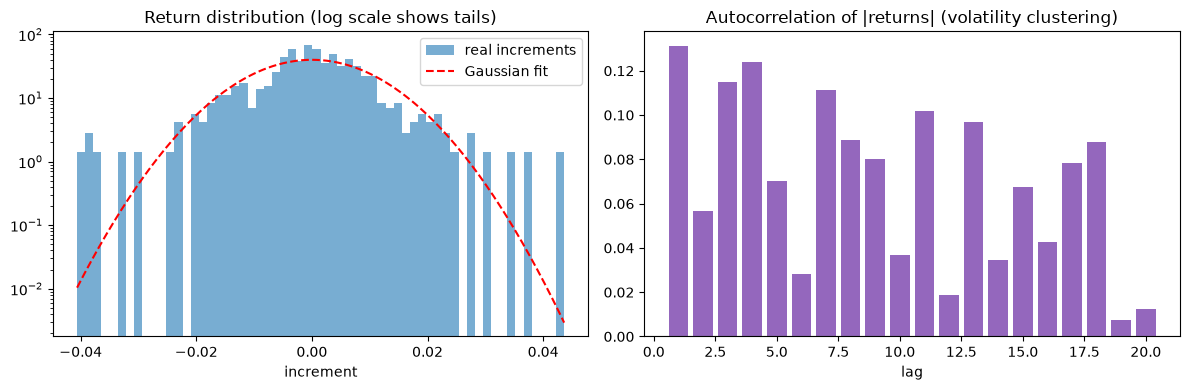

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(inc, bins=60, density=True, alpha=0.6, color='tab:blue', label='real increments')
xx = np.linspace(inc.min(), inc.max(), 200)
gauss = np.exp(-0.5 * (xx / inc.std())**2) / (inc.std() * np.sqrt(2 * np.pi))
axes[0].plot(xx, gauss, 'r--', label='Gaussian fit'); axes[0].set_yscale('log')
axes[0].set_title('Return distribution (log scale shows tails)'); axes[0].set_xlabel('increment'); axes[0].legend()

absr = np.abs(inc - inc.mean())
lags = range(1, 21)
acf = [np.corrcoef(absr[:-l], absr[l:])[0, 1] for l in lags]
axes[1].bar(list(lags), acf, color='tab:purple'); axes[1].axhline(0, color='gray', lw=0.8)
axes[1].set_title('Autocorrelation of |returns| (volatility clustering)'); axes[1].set_xlabel('lag')
plt.tight_layout(); plt.show()

## 2. In-distribution vs out-of-distribution performance
For each agent we evaluate on the synthetic market (trained regime) and on the real-path replay, using the same seeds. A robust agent keeps its risk-adjusted performance.

In [3]:
as_agent = AvellanedaStoikovAgent(cfg, ASConfig(gamma=0.1, kappa=40.0))
dqn = DQN.load(str(find('runs/dqn') / 'dqn.pt'))
ppo = PPO.load(str(find('runs/ppo') / 'ppo.pt'))

# Envs: synthetic vs replay, for discrete (AS/DQN) and continuous (PPO) agents.
syn_d = MarketMakingEnv(MMEnvConfig())
syn_c = MarketMakingEnv(MMEnvConfig(continuous_action=True))
rep_d = MarketMakingEnv(MMEnvConfig(replay_increments=inc))
rep_c = MarketMakingEnv(MMEnvConfig(continuous_action=True, replay_increments=inc))

N = 200
spec = [('AS', as_agent, syn_d, rep_d), ('DQN', dqn, syn_d, rep_d), ('PPO', ppo, syn_c, rep_c)]
rows = {}
for name, ag, es, er in spec:
    rs = evaluate(es, ag, n_episodes=N, seed0=5_000_000)
    rr = evaluate(er, ag, n_episodes=N, seed0=5_000_000)
    rows[name] = (rs, rr)
    print(f'{name:4} | synthetic  Sharpe {rs["sharpe"]:.2f} PnL {rs["pnl_mean"]:.2f} | real-path  Sharpe {rr["sharpe"]:.2f} PnL {rr["pnl_mean"]:.2f}')

AS   | synthetic  Sharpe 7.10 PnL 10.61 | real-path  Sharpe 6.79 PnL 10.49


DQN  | synthetic  Sharpe 7.36 PnL 9.96 | real-path  Sharpe 6.63 PnL 9.90


PPO  | synthetic  Sharpe 6.62 PnL 11.28 | real-path  Sharpe 6.34 PnL 11.01


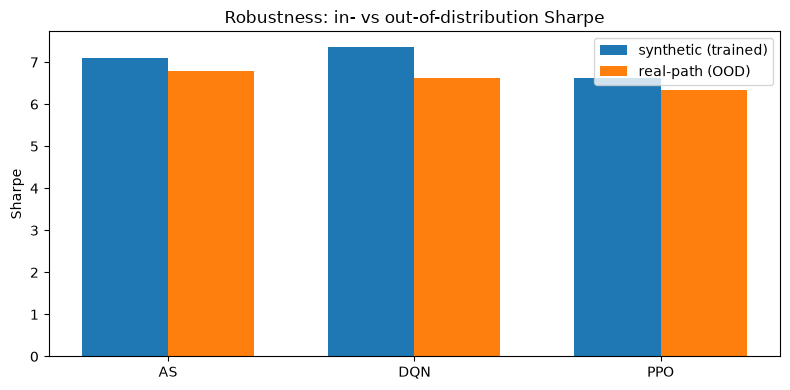

In [4]:
names = list(rows); x = np.arange(len(names)); w = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - w/2, [rows[n][0]['sharpe'] for n in names], w, label='synthetic (trained)', color='tab:blue')
ax.bar(x + w/2, [rows[n][1]['sharpe'] for n in names], w, label='real-path (OOD)', color='tab:orange')
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylabel('Sharpe'); ax.set_title('Robustness: in- vs out-of-distribution Sharpe'); ax.legend()
plt.tight_layout(); plt.show()

## 3. A single real-path episode
The fundamental now follows the (rescaled) real return path. Inventory should still stay controlled.

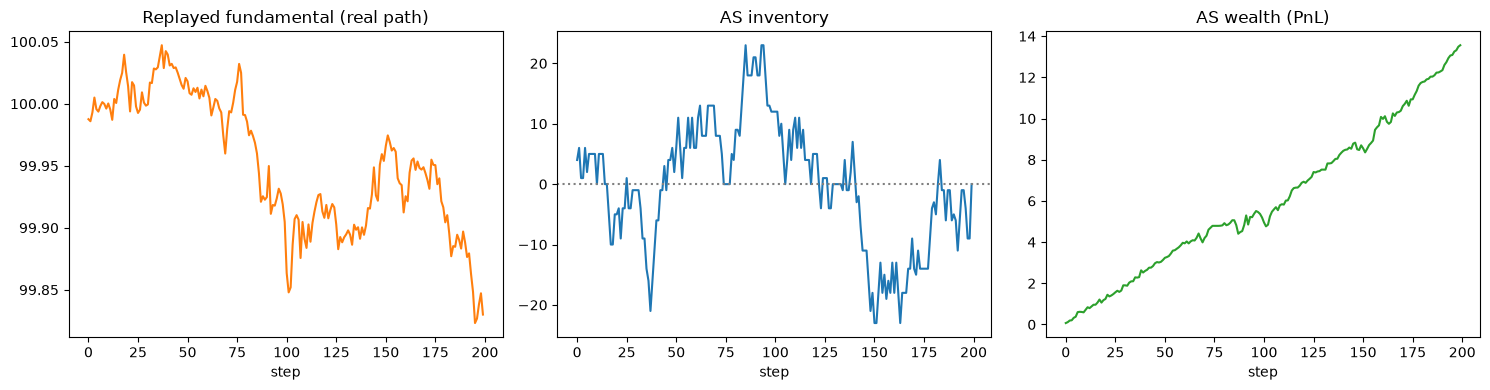

In [5]:
ep = run_episode(rep_d, as_agent, seed=5_000_123)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ep.fair, color='tab:orange'); axes[0].set_title('Replayed fundamental (real path)'); axes[0].set_xlabel('step')
axes[1].plot(ep.inventory, color='tab:blue'); axes[1].axhline(0, ls=':', color='gray'); axes[1].set_title('AS inventory'); axes[1].set_xlabel('step')
axes[2].plot(ep.wealth, color='tab:green'); axes[2].set_title('AS wealth (PnL)'); axes[2].set_xlabel('step')
plt.tight_layout(); plt.show()

---
**Takeaway.** The policies were trained on Gaussian fundamentals yet keep their risk-adjusted performance when the fundamental is replaced by a real, fat-tailed, volatility-clustered price path. They generalise because they condition on *inventory and microstructure state* - not on the specific return law. 

**Limitations (stated plainly).** Only the fundamental path is real here; order flow remains synthetic, and volatility is standardised to the training regime. A full sim-to-real study would replay a real limit-order book (e.g. LOBSTER) end-to-end and confront genuine non-stationarity in the flow - a natural extension, and the loader is already compatible.

Next: **Phase 6** - the written report tying the whole project together.